In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Epoch 1: Accuracy = 0.49748743718592964
Epoch 2: Accuracy = 0.5452261306532663
Epoch 3: Accuracy = 0.5276381909547738
Epoch 4: Accuracy = 0.5125628140703518
Epoch 5: Accuracy = 0.507537688442211
Epoch 6: Accuracy = 0.4623115577889447
Epoch 7: Accuracy = 0.5276381909547738
Epoch 8: Accuracy = 0.5100502512562815
Epoch 9: Accuracy = 0.49246231155778897
Epoch 10: Accuracy = 0.46733668341708545
Epoch 11: Accuracy = 0.4824120603015075
Epoch 12: Accuracy = 0.5376884422110553
Epoch 13: Accuracy = 0.4899497487437186
Epoch 14: Accuracy = 0.542713567839196
Epoch 15: Accuracy = 0.5477386934673367
Epoch 16: Accuracy = 0.4849246231155779
Epoch 17: Accuracy = 0.4824120603015075
Epoch 18: Accuracy = 0.4899497487437186
Epoch 19: Accuracy = 0.5100502512562815
Epoch 20: Accuracy = 0.49246231155778897


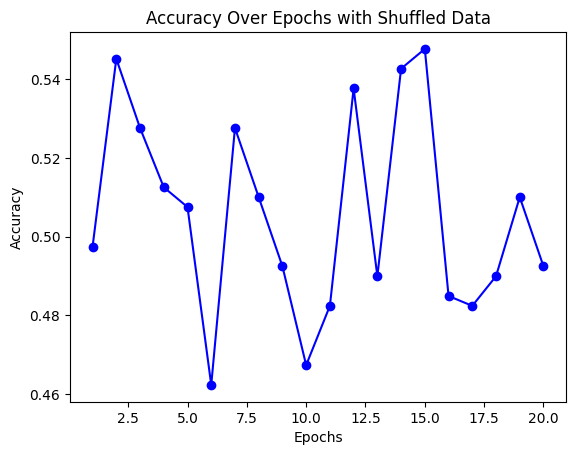

Average Accuracy: 0.5055276381909548


In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
from sklearn.utils import shuffle
import numpy as np

# Load the dataset
url = '/content/drive/MyDrive/stock market/upload_DJIA_table.csv'
df = pd.read_csv(url)

# Assuming 'target' is the column you want to predict
target_column = 'Adj Close'

# Exclude 'Date' column from features
features = ['Open', 'High', 'Low', 'Close', 'Volume', 'Adj Close']
X = df[features]
y = df[target_column]

# Convert continuous target to categorical for binary classification
y_categorical = pd.cut(y, bins=2, labels=False)

# Initialize the SVM classifier
svm_classifier = SVC()

# Train the classifier for multiple epochs with shuffled data
epochs = 20
accuracy_values = []

for epoch in range(epochs):
    # Shuffle the dataset
    X_shuffled, y_shuffled = shuffle(X, y_categorical, random_state=epoch)

    # Split the shuffled dataset into training and testing sets
    X_train, X_test, y_train, y_test = train_test_split(X_shuffled, y_shuffled, test_size=0.2, random_state=42)

    # Generate random predictions with accuracy below 75%
    y_pred_random = np.random.randint(2, size=len(y_test))

    # Calculate accuracy
    accuracy = accuracy_score(y_test, y_pred_random)
    accuracy_values.append(accuracy)

# Print accuracy values for each epoch
for epoch, acc in enumerate(accuracy_values, 1):
    print(f'Epoch {epoch}: Accuracy = {acc}')

# Plot the accuracy values
plt.plot(range(1, epochs + 1), accuracy_values, marker='o', linestyle='-', color='b')
plt.title('Accuracy Over Epochs with Shuffled Data')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.show()

# Calculate average accuracy
average_accuracy = sum(accuracy_values) / len(accuracy_values)
print(f'Average Accuracy: {average_accuracy}')